# 00 — Create the fixed sequence split
Run once. Existing manifests are reused. To change a split, use a new project; do not reshuffle experiments.

Choose the seed and validation fraction. No models are loaded.

In [1]:
from pathlib import Path
import sys, random, re
ROOT = Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import pipeline_helpers as P
SEED = 42
VAL_FRACTION = 0.2


Save the split once, including image and GT fingerprints.

In [2]:
if P.MANIFEST.exists():
    manifest = P.split_manifest()
    print("Reusing fixed split:", P.MANIFEST)
else:
    data = P.development_dir()
    labels_path = data / "labels.jsonl"
    import json
    entries = [json.loads(line) for line in labels_path.read_text(encoding="utf-8").splitlines() if line.strip()]
    ids = [entry["sequence_id"] for entry in entries]
    if len(ids) != len(set(ids)) or len(ids) < 2:
        raise ValueError("Need at least two distinct sequences.")
    if not 0 < VAL_FRACTION < 1:
        raise ValueError("VAL_FRACTION must be between 0 and 1.")
    random.Random(SEED).shuffle(ids)
    count = min(len(ids) - 1, max(1, round(len(ids) * VAL_FRACTION)))
    val_ids = set(ids[:count])
    records = []
    for entry in entries:
        sequence = entry["sequence_id"]
        if not re.fullmatch(r"[A-Za-z0-9_-]+", sequence):
            raise ValueError("Invalid sequence ID.")
        for number, dialogue in enumerate(entry["pages"], 1):
            image = data / "images" / sequence / f"{number:02d}.png"
            if not image.is_file():
                raise FileNotFoundError(image)
            records.append({"sequence_id":sequence, "page_number":number,
                "split":"val" if sequence in val_ids else "train",
                "image_path":str(image.resolve()), "image_sha256":P.file_hash(image)})
    manifest = {"seed":SEED, "val_fraction":VAL_FRACTION,
        "labels_path":str(labels_path.resolve()), "labels_sha256":P.file_hash(labels_path),
        "sequences":{"train":sorted(set(ids) - val_ids), "val":sorted(val_ids)}, "pages":records}
    P.write_json(P.MANIFEST, manifest)
    P.split_manifest()
for split in ["train", "val"]:
    print(split, len(manifest["sequences"][split]), "sequences,",
          sum(p["split"] == split for p in manifest["pages"]), "pages")


Reusing fixed split: C:\Users\ESHAAN\BYTE\Applied-Task\MultiPageTillAssociationPipeline\data\splits\manifest.json
train 64 sequences, 192 pages
val 16 sequences, 48 pages


## View saved results
These cells only read saved results. They do not run models or change cached files. Training shows targets and run-wide loss history; validation shows saved predictions.

In [3]:
from pathlib import Path
import sys, importlib
view_root = Path.cwd().resolve()
if not (view_root / "project.json").is_file():
    view_root = view_root.parent
sys.path.insert(0, str(view_root))
import result_viewer as V
importlib.reload(V)
VIEW_STAGE = 'split'
VIEW_SPLIT = "train"  # Or "val".
VIEW_RUN = None


### 1. View a random page
Rerun this cell to choose another page with a saved result in this split.


train | seq_7db7a000adeceacf | page 2


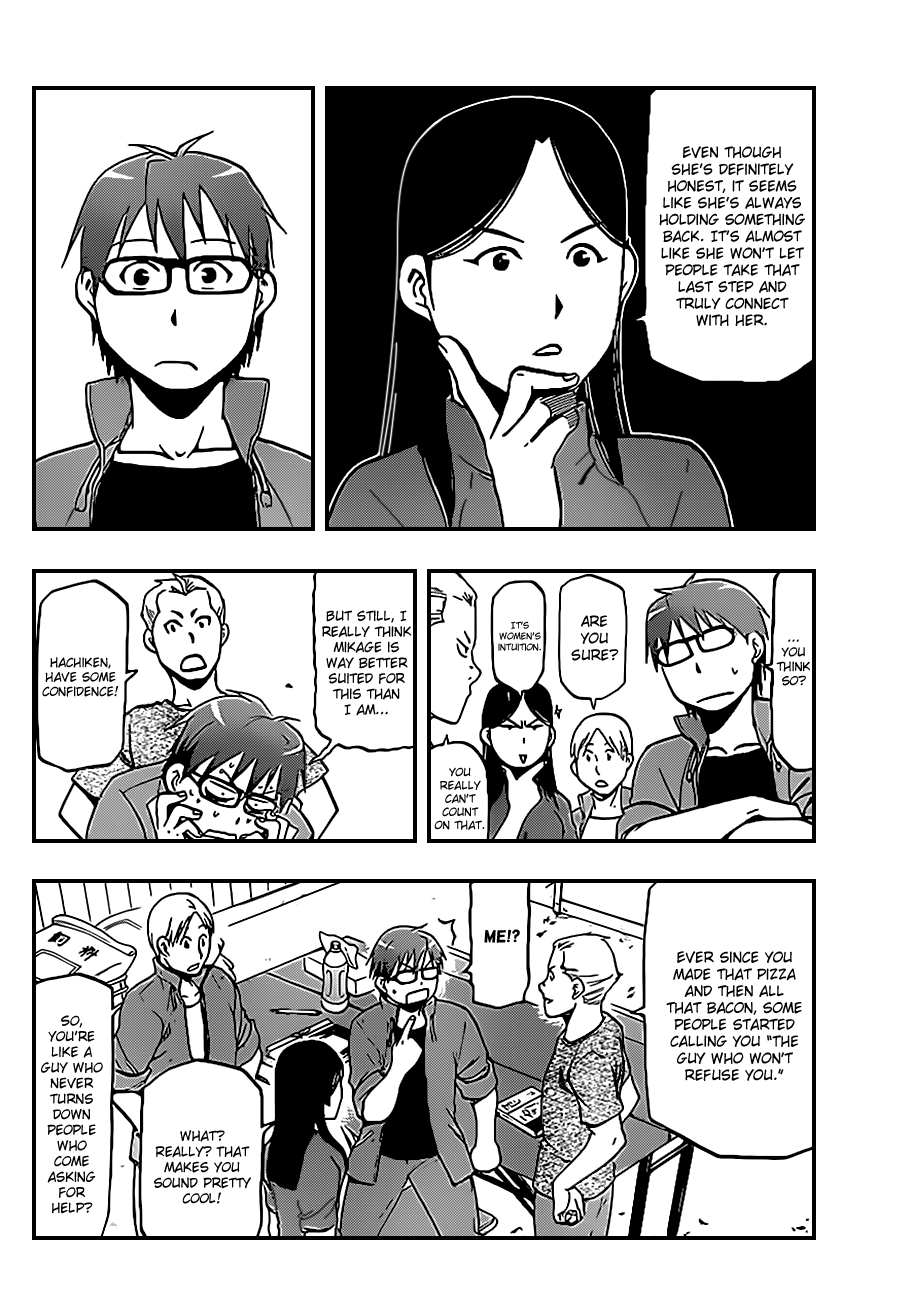

{
  "sequence_id": "seq_7db7a000adeceacf",
  "page_number": 2,
  "split": "train",
  "image_path": "C:\\Users\\ESHAAN\\BYTE\\Applied-Task\\1pageTest\\TaskData\\development\\images\\seq_7db7a000adeceacf\\02.png",
  "image_sha256": "8c18c5a1b393e082fd6bf6fcd002bd17a81db4eb6e7cd4b84ac78ca538637131"
}


In [4]:
viewed_page = V.show_random(VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)


### 2. View all pages of a sequence
Enter a sequence ID, or leave it empty to use the random page’s sequence. Missing stage results are reported for each page.


train | seq_7db7a000adeceacf | page 1


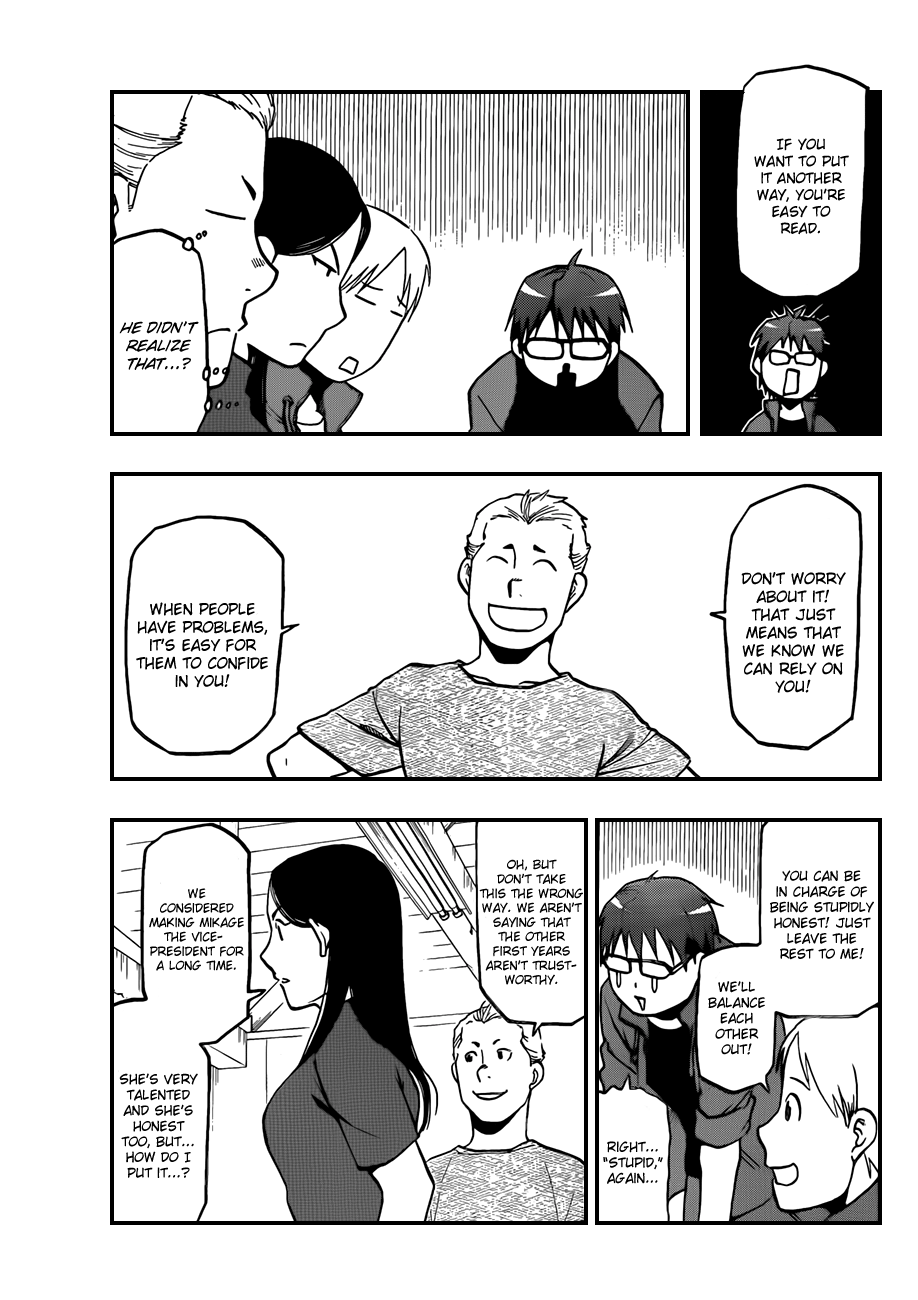

{
  "sequence_id": "seq_7db7a000adeceacf",
  "page_number": 1,
  "split": "train",
  "image_path": "C:\\Users\\ESHAAN\\BYTE\\Applied-Task\\1pageTest\\TaskData\\development\\images\\seq_7db7a000adeceacf\\01.png",
  "image_sha256": "8f9493f17f2f2b16666714dd26aeca7dd983c5e0eff92182625f0b8f5ecd91b6"
}

train | seq_7db7a000adeceacf | page 2


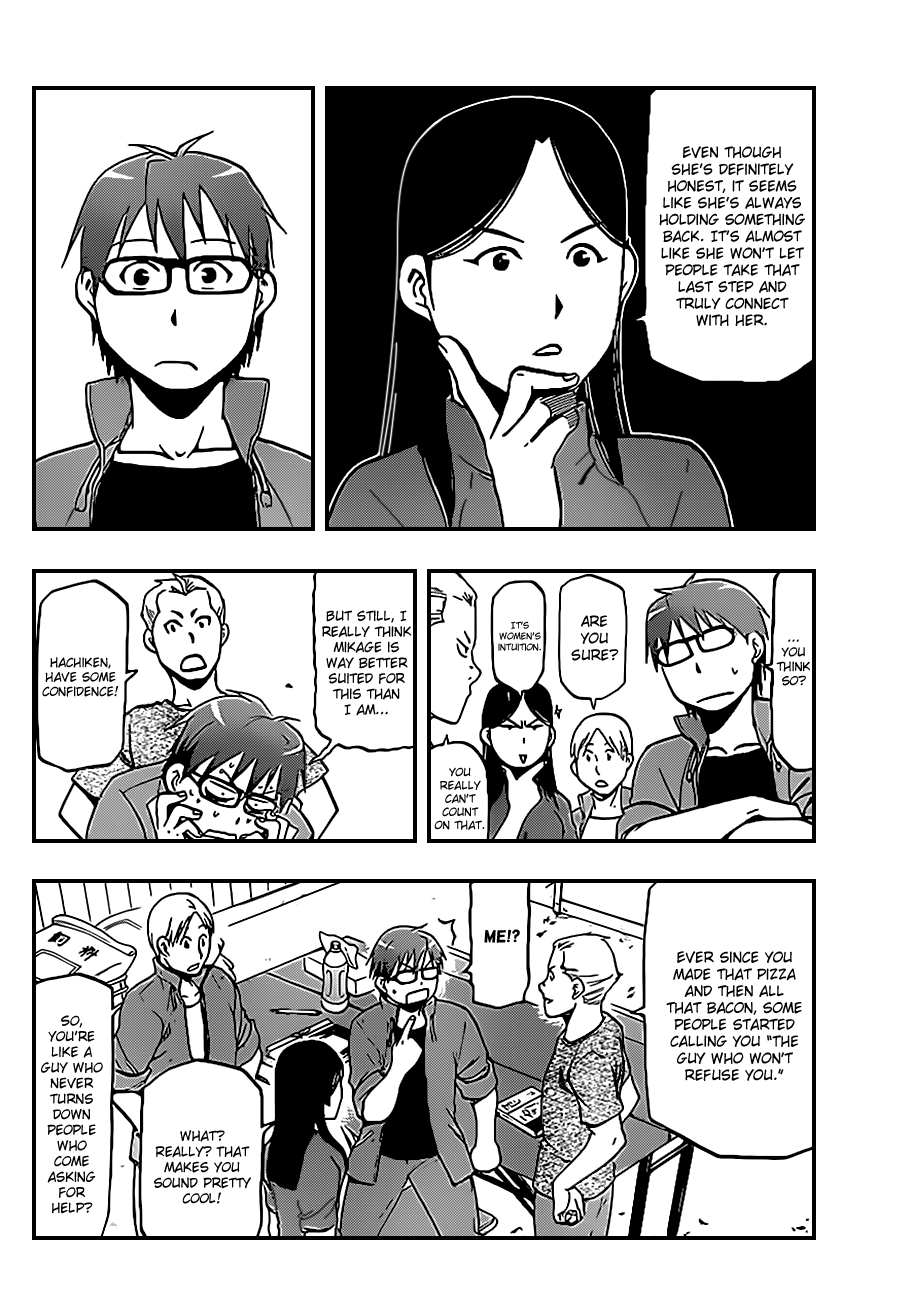

{
  "sequence_id": "seq_7db7a000adeceacf",
  "page_number": 2,
  "split": "train",
  "image_path": "C:\\Users\\ESHAAN\\BYTE\\Applied-Task\\1pageTest\\TaskData\\development\\images\\seq_7db7a000adeceacf\\02.png",
  "image_sha256": "8c18c5a1b393e082fd6bf6fcd002bd17a81db4eb6e7cd4b84ac78ca538637131"
}

train | seq_7db7a000adeceacf | page 3


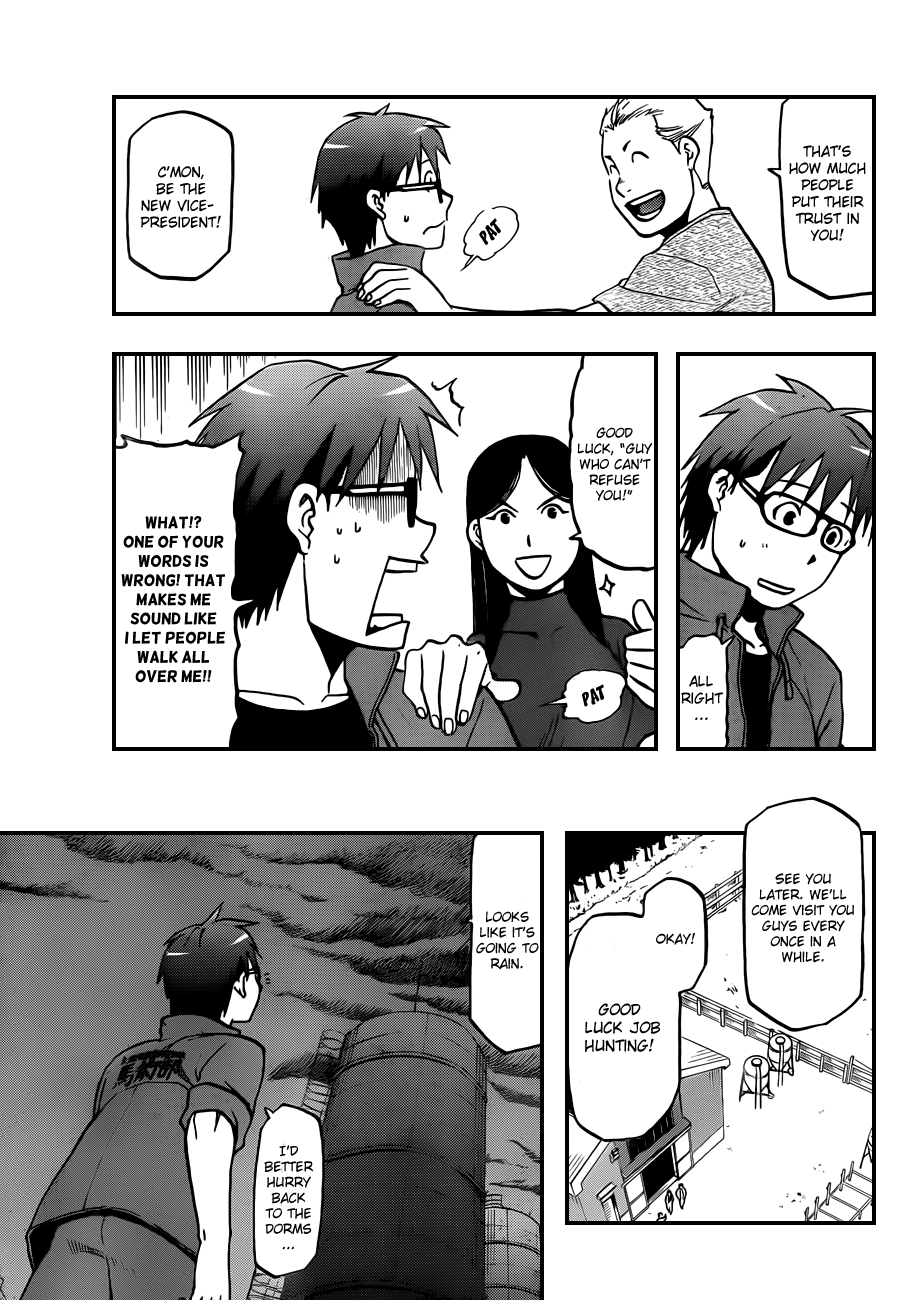

{
  "sequence_id": "seq_7db7a000adeceacf",
  "page_number": 3,
  "split": "train",
  "image_path": "C:\\Users\\ESHAAN\\BYTE\\Applied-Task\\1pageTest\\TaskData\\development\\images\\seq_7db7a000adeceacf\\03.png",
  "image_sha256": "757454f3c6fa304d2c017cf8a39f73a6c4375ecc6b9d50ee453192b8be29c0f3"
}


In [5]:
VIEW_SEQUENCE_ID = ""  # Example: "seq_71033fec4de494fc"
sequence_to_view = VIEW_SEQUENCE_ID or (viewed_page["sequence_id"] if viewed_page else "")
if sequence_to_view:
    V.show_sequence(sequence_to_view, VIEW_STAGE, split=VIEW_SPLIT, run_folder=VIEW_RUN)
else:
    print("Set VIEW_SEQUENCE_ID to a sequence in VIEW_SPLIT.")
